LAMDA files also list frequencies of radiative transitions, but only for informational purposes in principle. However, unfortunately, those frequencies are often more accurate than DeltaE/h. Here I check if the results differ if I use the frequencies from the data file or not.

# CO

For CO, the discrepancy between DeltaE/h and the listed frequencies is relatively small, so naively I expect no significant difference between the results

In [1]:
from pythonradex import radiative_transfer, helpers
from scipy import constants
import matplotlib.pyplot as plt
import numpy as np

In [2]:
geometry = "static slab"
line_profile_type = "rectangular"
width_v = 1 * constants.kilo
ext_background = helpers.generate_CMB_background(z=0)
T_dust = 0
tau_dust = 0

In [3]:
def run_models(datafilepath, N, Tkin, collider_densities):
    sources = {}
    for use_datafile_frequencies in (True, False):
        source = radiative_transfer.Source(
            datafilepath=datafilepath,
            geometry=geometry,
            line_profile_type=line_profile_type,
            width_v=width_v,
            use_datafile_frequencies=use_datafile_frequencies,
        )
        source.update_parameters(
            N=N,
            Tkin=Tkin,
            collider_densities=collider_densities,
            ext_background=ext_background,
            T_dust=T_dust,
            tau_dust=tau_dust,
        )
        source.solve_radiative_transfer()
        sources[str(use_datafile_frequencies)] = source
    return sources

In [4]:
CO_kwargs = {
    "datafilepath": "./co.dat",
    "N": 1e16 / constants.centi**2,
    "Tkin": 120,
    "collider_densities": {
        "para-H2": 2e2 / constants.centi**3,
        "ortho-H2": 6e2 / constants.centi**3,
    },
}
CO_sources = run_models(**CO_kwargs)

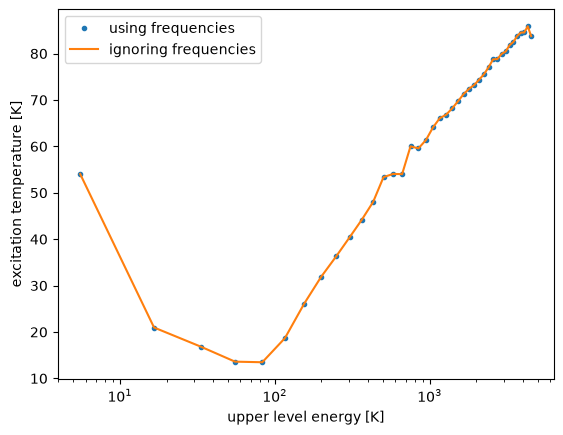

In [5]:
def plot_Tex(sources, xscale="log", yscale="log"):
    E_up = [
        trans.up.E / constants.k
        for trans in sources["True"].emitting_molecule.rad_transitions
    ]
    E_up = sorted(E_up)
    fig, ax = plt.subplots()
    ax.plot(
        E_up,
        sources["True"].Tex,
        marker=".",
        linestyle="None",
        label="using frequencies",
    )
    ax.plot(E_up, sources["False"].Tex, label="ignoring frequencies")
    ax.set_xlabel("upper level energy [K]")
    ax.set_ylabel("excitation temperature [K]")
    ax.legend(loc="best")
    ax.set_xscale(xscale)
    ax.set_yscale(yscale)


plot_Tex(sources=CO_sources, yscale="linear")

# o-H2O

Here there are some transitions that are more problematic, e.g. transition from level 269 to 268: frequency (4.17191 GHz) inconsistent with level energies (DeltaE corresponds to 3.50044 GHz). relative difference: 18%

/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/atomic_transition.py:350: UserWarning: inconsistency between DeltaE/h and the frequency listed in LAMDA file for transition 14-13.  DeltaE/h=22.235007024944174 GHz, listed frequency = 21.5549, relative difference =3.1%
  warnings.warn("inconsistency between DeltaE/h and the frequency listed in LAMDA file"
/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/atomic_transition.py:350: UserWarning: inconsistency between DeltaE/h and the frequency listed in LAMDA file for transition 71-70.  DeltaE/h=12.008786490101174 GHz, listed frequency = 11.67769, relative difference =2.8%
  warnings.warn("inconsistency between DeltaE/h and the frequency listed in LAMDA file"
/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/atomic_transition.py:350: UserWarning: inconsistency between DeltaE/h and the frequency listed in LAMDA file for transition 85-84.  DeltaE/h=26.83412312312075 G

7-6: tau_nu0 = -0.00264
13-11: tau_nu0 = -1.69e-06
14-13: tau_nu0 = -2.75e-07
16-15: tau_nu0 = -2.36e-07
20-17: tau_nu0 = -7.79e-08
20-19: tau_nu0 = -1.39e-07
24-22: tau_nu0 = -1.12e-08
25-21: tau_nu0 = -2.83e-07
27-26: tau_nu0 = -1.37e-09
30-26: tau_nu0 = -4.83e-08
30-28: tau_nu0 = -5.24e-09
33-32: tau_nu0 = -3.67e-10
37-34: tau_nu0 = -3.04e-09
39-36: tau_nu0 = -2.13e-10
39-38: tau_nu0 = -2.53e-10
45-44: tau_nu0 = -3.45e-12
53-51: tau_nu0 = -2.25e-13
64-62: tau_nu0 = -2.63e-15
67-66: tau_nu0 = -1.9e-13
85-84: tau_nu0 = -6.91e-14
92-89: tau_nu0 = -9.62e-18
93-87: tau_nu0 = -6.68e-13
93-91: tau_nu0 = -3.63e-14
98-77: tau_nu0 = -2e-23
100-95: tau_nu0 = -7.81e-14
101-95: tau_nu0 = -1.57e-15
107-105: tau_nu0 = -1.16e-15
108-89: tau_nu0 = -5.55e-25
108-106: tau_nu0 = -2.24e-24
109-106: tau_nu0 = -1.27e-17
113-95: tau_nu0 = -2.78e-16
113-105: tau_nu0 = -7.7e-14
113-112: tau_nu0 = -3.63e-15
121-109: tau_nu0 = -1.66e-23
121-120: tau_nu0 = -4.65e-26
124-120: tau_nu0 = -1.42e-18
129-119: tau_nu0

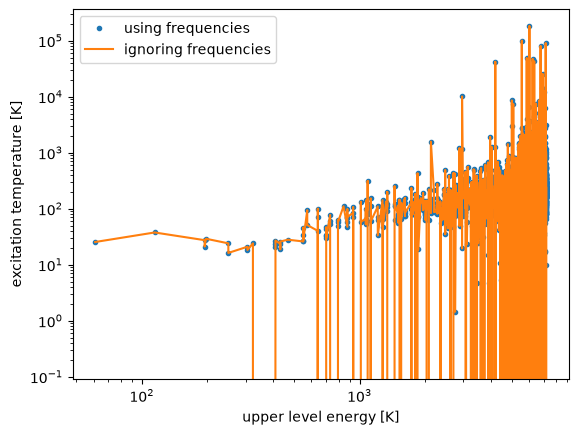

In [6]:
oH2O_kwargs = {
    "datafilepath": "./oh2o@rovib.dat",
    "N": 1e16 / constants.centi**2,
    "Tkin": 400,
    "collider_densities": {"H2": 2e4 / constants.centi**3},
}
oH2O_sources = run_models(**oH2O_kwargs)
plot_Tex(sources=oH2O_sources)

# NO

transition from level 86 to 84: frequency (0.016359 GHz) inconsistent with level energies (DeltaE corresponds to 0.0188577 GHz). relative difference: 14%

/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/atomic_transition.py:350: UserWarning: inconsistency between DeltaE/h and the frequency listed in LAMDA file for transition 96-95.  DeltaE/h=0.013204598647068374 GHz, listed frequency = 0.0123789, relative difference =6.5%
  warnings.warn("inconsistency between DeltaE/h and the frequency listed in LAMDA file"
/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/atomic_transition.py:350: UserWarning: inconsistency between DeltaE/h and the frequency listed in LAMDA file for transition 86-85.  DeltaE/h=0.013260509939739047 GHz, listed frequency = 0.013905, relative difference =4.7%
  warnings.warn("inconsistency between DeltaE/h and the frequency listed in LAMDA file"
/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/atomic_transition.py:350: UserWarning: inconsistency between DeltaE/h and the frequency listed in LAMDA file for transition 99-98.  DeltaE/h=0.01671447880

98-97: tau_nu0 = -1.14e-05
95-94: tau_nu0 = -1.21e-05
96-95: tau_nu0 = -1.61e-05
86-84: tau_nu0 = -1.88e-05
66-65: tau_nu0 = -0.000278
83-82: tau_nu0 = -1.9e-05
99-98: tau_nu0 = -1.49e-05
85-83: tau_nu0 = -2.46e-05
73-72: tau_nu0 = -1.89e-05
73-71: tau_nu0 = -6.5e-05
71-70: tau_nu0 = -1.92e-05
72-70: tau_nu0 = -9.26e-05
87-86: tau_nu0 = -2.43e-05
75-74: tau_nu0 = -3.15e-05
68-67: tau_nu0 = -0.000375
74-71: tau_nu0 = -2.47e-05
67-65: tau_nu0 = -1.25e-05
66-64: tau_nu0 = -1.26e-05
75-73: tau_nu0 = -2.44e-05
54-53: tau_nu0 = -0.000721
68-66: tau_nu0 = -1.67e-05
86-83: tau_nu0 = -0.000146
55-53: tau_nu0 = -3.12e-06
69-67: tau_nu0 = -1.68e-05
84-82: tau_nu0 = -0.000142
54-52: tau_nu0 = -3.49e-06
67-64: tau_nu0 = -0.000294
87-85: tau_nu0 = -0.000136
55-52: tau_nu0 = -0.000605
73-70: tau_nu0 = -0.000131
69-66: tau_nu0 = -0.000391
56-55: tau_nu0 = -0.000981
75-71: tau_nu0 = -0.000165
56-54: tau_nu0 = -4.41e-06
57-55: tau_nu0 = -4.69e-06
86-82: tau_nu0 = -5.59e-05
48-47: tau_nu0 = -0.00111
49-4

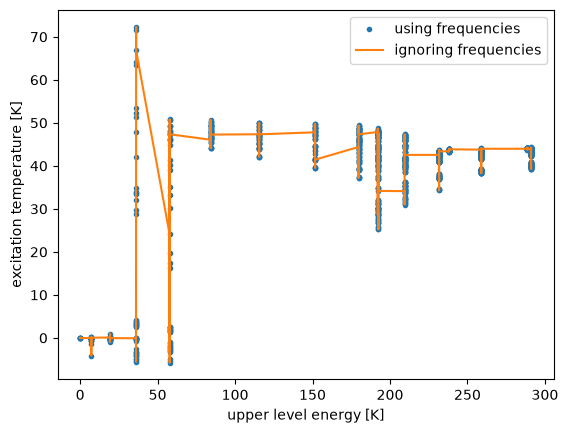

In [7]:
NO_kwargs = {
    "datafilepath": "./no.dat",
    "N": 1e18 / constants.centi**2,
    "Tkin": 50,
    "collider_densities": {"H2": 2e5 / constants.centi**3},
}
NO_sources = run_models(**NO_kwargs)
plot_Tex(sources=NO_sources, xscale="linear", yscale="linear")

# o-H2CO

two transitions have big differences:
transition from level 16 to 15: frequency (0.000655 GHz) inconsistent with level energies (DeltaE corresponds to 0.00299792 GHz). relative difference: 130%
transition from level 19 to 18: frequency (0.004573 GHz) inconsistent with level energies (DeltaE corresponds to 0.00299792 GHz). relative difference: 42%

/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/atomic_transition.py:350: UserWarning: inconsistency between DeltaE/h and the frequency listed in LAMDA file for transition 15-14.  DeltaE/h=0.0029979245795080135 GHz, listed frequency = 0.000655, relative difference =1.3e+02%
  warnings.warn("inconsistency between DeltaE/h and the frequency listed in LAMDA file"
/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/atomic_transition.py:350: UserWarning: inconsistency between DeltaE/h and the frequency listed in LAMDA file for transition 18-17.  DeltaE/h=0.0029979245800757083 GHz, listed frequency = 0.004573, relative difference =42%
  warnings.warn("inconsistency between DeltaE/h and the frequency listed in LAMDA file"
/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/atomic_transition.py:350: UserWarning: inconsistency between DeltaE/h and the frequency listed in LAMDA file for transition 21-20.  DeltaE/h=0.0179875

35-34: tau_nu0 = -0.00017
39-38: tau_nu0 = -7.15e-05
35-34: tau_nu0 = -0.000168
39-38: tau_nu0 = -7.17e-05


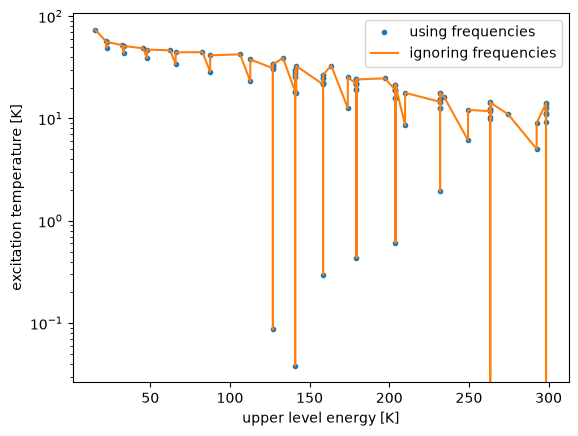

In [8]:
oH2CO_kwargs = {
    "datafilepath": "./oh2co-h2.dat",
    "N": 1e17 / constants.centi**2,
    "Tkin": 50,
    "collider_densities": {
        "para-H2": 2e4 / constants.centi**3,
        "ortho-H2": 6e2 / constants.centi**3,
    },
}
oH2CO_sources = run_models(**oH2CO_kwargs)
plot_Tex(sources=oH2CO_sources, xscale="linear")

# o-H2S

This one also has some big differences:
transition from level 16 to 6: frequency (3016.06592 GHz) inconsistent with level energies (DeltaE corresponds to 573.242 GHz). relative difference: 140%
transition from level 17 to 16: frequency (2040.91271 GHz) inconsistent with level energies (DeltaE corresponds to 4483.73 GHz). relative difference: 75%
transition from level 23 to 16: frequency (3028.38859 GHz) inconsistent with level energies (DeltaE corresponds to 5471.21 GHz). relative difference: 57%

/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/atomic_transition.py:350: UserWarning: inconsistency between DeltaE/h and the frequency listed in LAMDA file for transition 15-5.  DeltaE/h=573.2421527155402 GHz, listed frequency = 3016.06592, relative difference =1.4e+02%
  warnings.warn("inconsistency between DeltaE/h and the frequency listed in LAMDA file"
/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/atomic_transition.py:350: UserWarning: inconsistency between DeltaE/h and the frequency listed in LAMDA file for transition 16-15.  DeltaE/h=4483.734974867539 GHz, listed frequency = 2040.91271, relative difference =75%
  warnings.warn("inconsistency between DeltaE/h and the frequency listed in LAMDA file"
/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/atomic_transition.py:350: UserWarning: inconsistency between DeltaE/h and the frequency listed in LAMDA file for transition 22-15.  DeltaE/h=5471.212358500

7-6: tau_nu0 = -0.000184
13-12: tau_nu0 = -4.19e-05
13-12: tau_nu0 = -4.5e-05
22-17: tau_nu0 = -5.39e-11


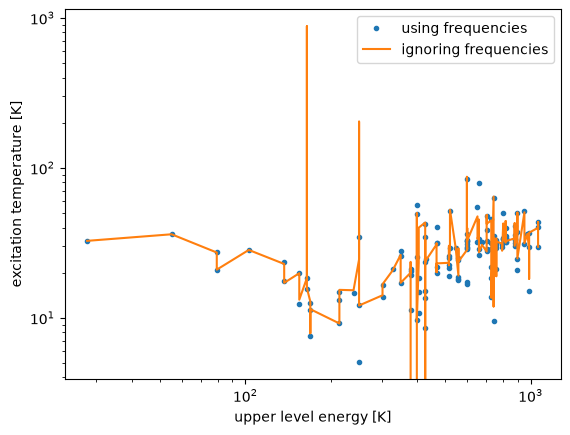

In [9]:
oH2S_kwargs = {
    "datafilepath": "./oh2s.dat",
    "N": 1e17 / constants.centi**2,
    "Tkin": 50,
    "collider_densities": {
        "para-H2": 2e4 / constants.centi**3,
        "ortho-H2": 6e2 / constants.centi**3,
    },
}
oH2S_sources = run_models(**oH2S_kwargs)
plot_Tex(sources=oH2S_sources)

For this last one, it looks quite messed up, except for the low energy levels